> **Recorded research notebook.** Executed outputs are retained from the completed study. Empirical recomputation requires the separately retained input snapshots described in `data/README.md`. Run `python scripts/reproduce_public.py` for checks and a synthetic demonstration using only this public repository. Historical publication-stage notes below describe the notebook execution date; the final PDF is now in `paper/final/Information-Diffusion-Final-Paper.pdf`.

# 02 · Synthetic validation and failure cases

Simulation asks whether the estimator behaves sensibly when the mechanism is known. Six cases separate immediate adjustment, gradual adjustment, reversal, no response, continuing drift and stale quotes. Noise consists of heteroskedastic Student-t increments with serial dependence within events.

As Morris, White and Crowther (2019) explain in their simulation-study tutorial, performance estimates need a defined data-generating mechanism and Monte Carlo uncertainty. A nominal 95% interval is not established by one visually convincing curve. The initial design uses 200 replications at each of N=40 and N=80; N=16 and N=30 were added transparently after the coverage audit, without selecting a new empirical specification.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'diffusion/common.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from diffusion.common import ROOT, design, sha256
from diffusion.reporting import table
from diffusion.presentation import show_table, show_json, show_figure, show_plot, equation
pd.set_option('display.max_columns', 12)
print('Project:', ROOT.name)
print('Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.')

Project: Information-Diffusion-Research
Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.


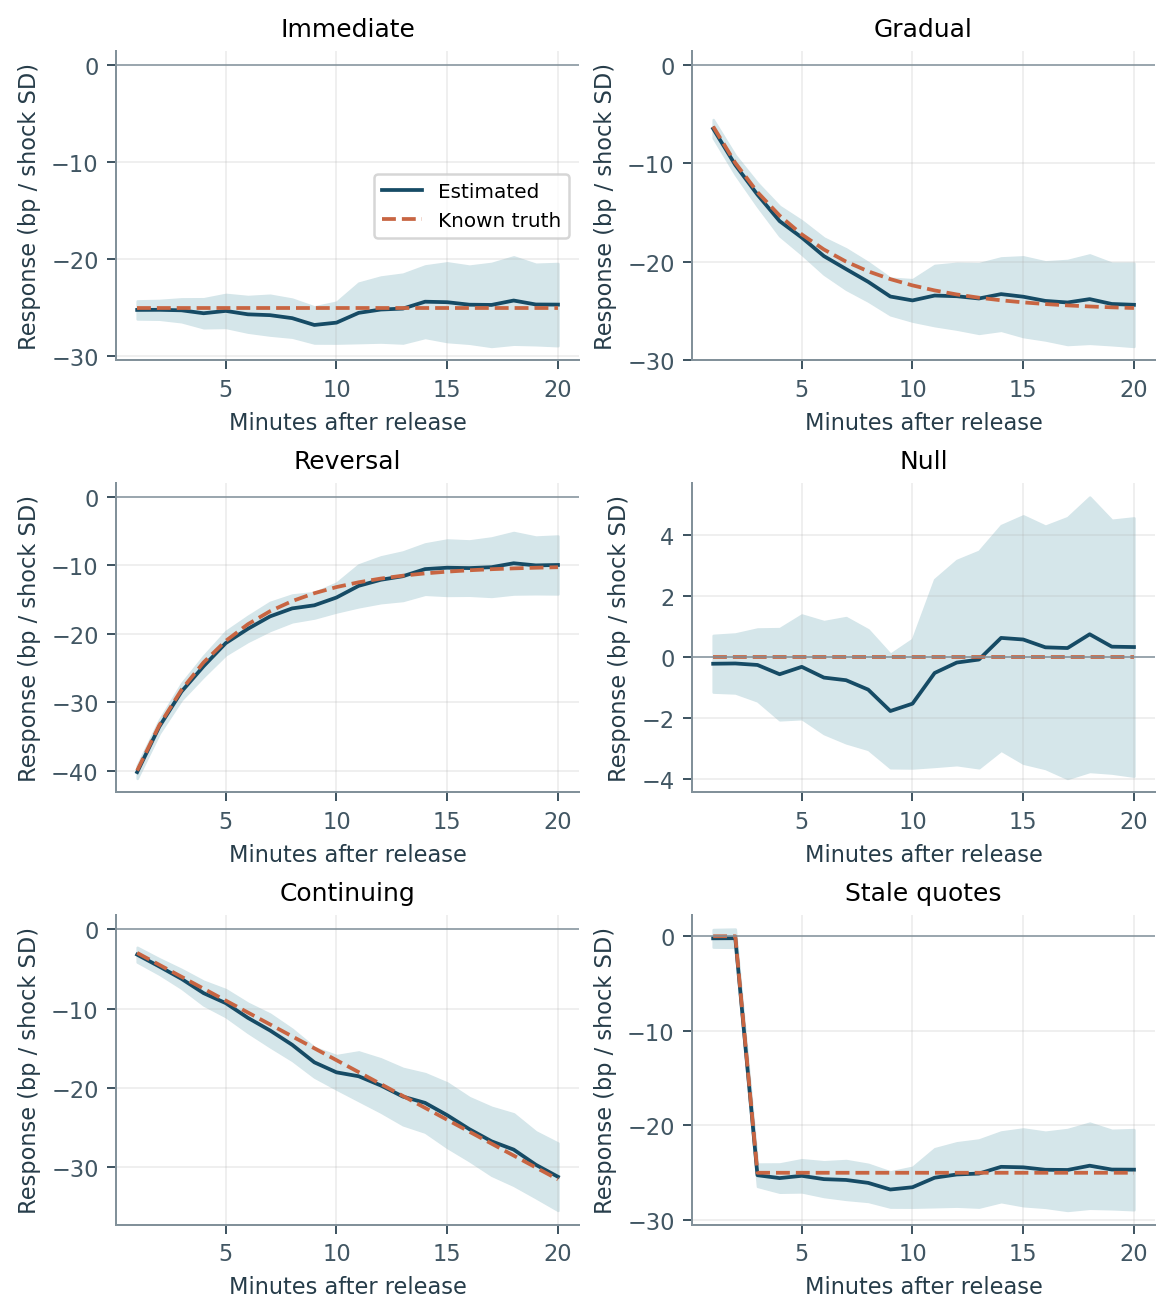

Figure 1. Six known mechanisms and their estimated responses. Shading is an event wild-bootstrap simultaneous band across 20 horizons; these are simulated data.

Fresh 80-event fit and 1,999-draw simultaneous band reproduce the saved example.


In [2]:
from diffusion.synthetic import sample, truth, CASES
from diffusion.statistics import ols_hc3, wild_band, fit_adjustment
h = np.arange(1,21)
x,y = sample('gradual',80,20261016)
fit = ols_hc3(x,y)
band = wild_band(fit,reps=1999)
saved = table('synthetic-curves.csv').query("case=='gradual'")
np.testing.assert_allclose(fit['coef'][1], saved.estimated, rtol=1e-9)
np.testing.assert_allclose(band['lo'], saved.lo, rtol=1e-9)
print('Fresh 80-event fit and 1,999-draw simultaneous band reproduce the saved example.')
show_figure(1)

In [3]:
recovered = fit_adjustment(h,truth('gradual',h))
np.testing.assert_allclose([recovered['amplitude_bps'],recovered['first_minute_fraction'],recovered['k_per_minute']],[-25,.25,.22],rtol=1e-5)
show_json({k:v for k,v in recovered.items() if k!='predicted'})
print('Noiseless parameter recovery is exact to numerical tolerance; this is not empirical speed identification.')
equation(17)

{
  "success": true,
  "amplitude_bps": -25.0,
  "first_minute_fraction": 0.25,
  "k_per_minute": 0.22000000000000003,
  "normalised_rmse": 6.429053626476672e-17,
  "t50_minutes": 2.8430232186734745,
  "t90_minutes": 10.15865009337393,
  "remaining_half_life_minutes": 3.1506690025452055,
  "boundary": false
}

Equation (17). Monte Carlo standard error.
\mathrm{MCSE}(\hat p)=\sqrt{\hat p(1-\hat p)/M}
M is the number of independent simulation replications; simulation performance estimates have their own uncertainty.

Noiseless parameter recovery is exact to numerical tolerance; this is not empirical speed identification.


In [4]:
initial = table('synthetic-validation.csv').assign(stage='initial N=40/80')
extra = table('synthetic-small-sample.csv')
results = pd.concat([initial,extra],ignore_index=True)
show_table(results[['stage','case','n','pointwise_coverage','simultaneous_coverage','late_rejection_rate']], 'Table N02.1. Simulation coverage and late-response rejection rates.')
null = results.query("case=='null'")[['n','pointwise_coverage','coverage_mcse','simultaneous_coverage','simultaneous_mcse','late_rejection_rate','late_rejection_mcse']].sort_values('n')
assert len(null)==4 and set(results['case'])==set(CASES)
show_table(null, 'Table N02.2. Null-case performance with Monte Carlo standard errors.')
assert len(results)==24
assert results.replications.sum()==4800
raw = pd.concat([table('synthetic-replications.csv'),table('synthetic-small-sample-replications.csv')])
assert len(raw)==4800
for (case,n),g in raw.groupby(['case','n']):
    row=results[(results.case==case)&(results.n==n)].iloc[0]
    assert np.isclose(g.terminal_covered.mean(),row.pointwise_coverage)
    assert np.isclose(g.path_covered.mean(),row.simultaneous_coverage)
print('All 4,800 scenario fits reconcile with the saved replication-level records.')

stage,case,n,pointwise_coverage,simultaneous_coverage,late_rejection_rate
initial N=40/80,immediate,40,0.940,0.930,0.045
initial N=40/80,immediate,80,0.960,0.945,0.085
initial N=40/80,gradual,40,0.940,0.930,0.880
initial N=40/80,gradual,80,0.960,0.945,0.985
initial N=40/80,reversal,40,0.940,0.930,0.985
initial N=40/80,reversal,80,0.960,0.945,1.000
initial N=40/80,null,40,0.940,0.930,0.045
initial N=40/80,null,80,0.960,0.945,0.085
initial N=40/80,continuing,40,0.940,0.930,1.000
initial N=40/80,continuing,80,0.960,0.945,1.000


n,pointwise_coverage,coverage_mcse,simultaneous_coverage,simultaneous_mcse,late_rejection_rate,late_rejection_mcse
16,0.960,0.014,0.945,0.016,0.060,0.017
30,0.950,0.015,0.955,0.015,0.065,0.017
40,0.940,0.017,0.930,0.018,0.045,0.015
80,0.960,0.014,0.945,0.016,0.085,0.020


All 4,800 scenario fits reconcile with the saved replication-level records.


## Reading the imperfections

Late-response false-positive rates in the null case are 6.0%, 6.5%, 4.5% and 8.5% at N=16, 30, 40 and 80. The N=80 rate is above nominal and is retained, with MCSE about 2.0 percentage points. The supplementary N=16 gradual-response rejection rate is only 41.5%, illustrating low power in a sample the size of the later statement period.

The six cases share random noise within each sample size and replication, deliberately making comparisons paired. Therefore 4,800 scenario fits involve 800 distinct noise draws, not 4,800 independent experiments. Coverage repeats across additive cases because the fixed signal changes while regression-error draws do not. Each case has 200 independent replications; uncertainty should not be computed by pooling paired cases as independent observations.

As MacKinnon and White (1985) motivate, leverage adjustment improves heteroskedastic covariance estimation; it does not eliminate every small-sample error. As Davidson and Flachaire (2008) explain, wild-bootstrap behaviour depends on the design and implementation. These tests are evidence about the stated simulations, not a guarantee for market data.

In [5]:
equation(11)
equation(12)
equation(13)
print('Heavy simulations can be rerun with:')
print('  python scripts/run_synthetic.py')
print('  python scripts/run_small_sample.py')
print('The executed notebook independently recomputes an example and audits every saved replication group.')

Equation (11). HC3 covariance estimator.
\widehat V_{\mathrm{HC3}}=(X^{\mathsf T}X)^{-1}\!\left[\sum_e\frac{\hat\varepsilon_e^2\,\mathbf{x}_e^{R}(\mathbf{x}_e^{R})^{\mathsf T}}{(1-\ell_e)^2}\right](X^{\mathsf T}X)^{-1}
Here x superscript R is a regression row, distinct from the rate-input vector; ℓ is OLS leverage.

Equation (12). Event-path wild-bootstrap draw.
Y^*_{e}(h)=\widehat Y_e(h)+v_e\frac{\widehat\varepsilon_e(h)}{1-\ell_e},\qquad \Pr(v_e=1)=\Pr(v_e=-1)=\tfrac12
One sign per event is shared across all horizons, retaining within-event path dependence.

Equation (13). Simultaneous response band.
\mathcal{B}_h=\left[\hat\beta_h-c_{0.95}\,\widehat{\mathrm{se}}_h,\ \hat\beta_h+c_{0.95}\,\widehat{\mathrm{se}}_h\right]
The critical value is the 95th percentile of the bootstrap maximum absolute studentised coefficient error across the 20 horizons.

Heavy simulations can be rerun with:
  python scripts/run_synthetic.py
  python scripts/run_small_sample.py
The executed notebook independently recomputes an example and audits every saved replication group.


## Milestone outcome

The unrestricted curves can represent mechanisms that a monotone adjustment model cannot. Synthetic quote staleness can imitate delayed information incorporation. Reversals and continuing drift must not be forced into a single half-life. The empirical analysis therefore starts with unrestricted horizon regressions and makes speed reporting conditional on diagnostics.